# Introducing pyHSP

## Getting Started

pyHSP implements Hansen Solubility Parameter (HSP) fitting in python, taking a machine learning inspired approach; afterall, while HSP is grounded in physics it is still an emperical relationship and is inherently a classification task (in ML language). Specifically we implement a scikit-learn compatible API, fit the HSP sphere using a logistic function and use classification metrics (the F1 score) for evaluation.



### Importing data

The following code loads an example of polylactic acid, originally published on the HSPiP website. The data is loaded as a pandas dataframe for convenient inspection. We use the following column naming conventions, paying attention to capitilisation:
* dD: the dispersion solubility parameter
* dP: the polar solubility parameter
* dH: the hydrogen bonding solubility parameter
* MVol: the molar volume of a solvent
* Score: the binary solubility of the solute in the solvent; 1 for soluble, 0 for insoluble (this follows the HSPiP convention)

The dataframe index is typically the solvent name, but it can be whatever you want.

In [49]:
from pyHSP.examples import load_pla

pla = load_pla()
pla # display the dataframe

,dD,dP,dH,MVol,Score
Pyridine,19.0,8.8,5.9,80.9,1
N-Methyl-2-Pyrrolidone (NMP),18.0,12.3,7.2,96.6,1
Methylene Dichloride (Dichloromethane),17.0,7.3,7.1,64.4,1
"1,3-Dioxolane",18.1,6.6,9.3,69.9,1
Methyl Ethyl Ketone (MEK),16.0,9.0,5.1,90.2,1
Tetrahydrofuran (THF),16.8,5.7,8.0,81.9,1
Chloroform,17.8,3.1,5.7,80.5,1
Acetone,15.5,10.4,7.0,73.8,1
Dimethyl Formamide (DMF),17.4,13.7,11.3,77.4,1
Dimethyl Sulfoxide (DMSO),18.4,16.4,10.2,71.3,1


### Fitting a sphere

The `ClassicSphere` class is the main scikit-learn compatible estimator used for fitting. For most cases you can use the default parameters when instantiating the object.

In [50]:
from pyHSP.sphere import ClassicSphere

sphere = ClassicSphere()

Scikit-learn estimators expect to receive feature data `X` and targets `y` as separate parameters; `X` must be a 2D array and `y` must be a 1D array. Pandas dataframes and series map onto this structure but we still need to make separate parameters. The `ClassicSphere` estimator only accepts arrays with 3 columns (shape `(n, 3)`) which must be in the order 'dD', 'dP', 'dH'.

We can now call the `.fit()` method. This returns the fitted object, as per scikit-learn.

In [51]:
X = pla[['dD', 'dP', 'dH']]
y = pla['Score']

sphere.fit(X, y)

,graded,False
,da,False
,bounds,None
,alpha,0
,beta,10.0
,initialisation,'mean'
,init_sigma,3.0
,loss,None
,squared_dist,False
,eps,1e-12
,method,'L-BFGS-B'


The fit parameters of the sphere are now available in the `coef_` attribute, which is a pandas series. These map to the HSP coordinates of the centre of the sphere, and the radius.

In [52]:
sphere.coef_

dD        21.807170
dP         8.288672
dH         9.330181
radius    14.340514
dtype: float64

### Making predictions

Now we have a fitted sphere we can use it to make solubility predictions for new solvents. We'll use some made up values, passing them as a numpy array, which then returns a numpy array containing the predicted solubility classification - 1 for soluble and 0 for insoluble.

In [53]:
import numpy as np

new_solvents = np.array(
    [[16.2, 7.9, 18.3],  # expect 0 - insoluble
     [17.3, 1.8, 4.1]]  # expect 1 - soluble
)
sphere.predict(new_solvents)

array([0, 1], dtype=uint8)

### Extra support for dataframes

If you have an array-like object of data the `HSP()` function offers a quick way to convert it to a dataframe, and passing a dataframe to `predict()` returns a series with the same index:

In [54]:
from pyHSP.pandas import HSP

new_solvents = HSP(new_solvents, index=['A', 'B'])
new_solvents

,dD,dP,dH
A,16.2,7.9,18.3
B,17.3,1.8,4.1


In [55]:
sphere.predict(new_solvents)

A    0
B    1
dtype: uint8

All estimator methods of expect array-like data. Dataframes and series are supported (as already shown) but are treated as arrays with the exception of maintaining the index. Dataframes must follow the dD, dP, dH column order and passing dataframes with addtional columns is not supported:





However, typical HSP experiments store the solvent HSPs and scores in the same table (whether that is a dataframe, spreadsheet or the like) and may include extra columns much like our example PLA data. To make working with this data structure a little easier, pyHSP estimators have a `pd` accessor. This can take a dataframe, extract the relevent columns, and pass it to the various methods of the estimator:

In [56]:
# this will work, note that y is not required
sphere = ClassicSphere().pd.fit(pla)
sphere.coef_

dD        21.796383
dP         8.301431
dH         9.333167
radius    14.323261
dtype: float64

In [57]:
pla['Prediction'] = sphere.pd.predict(pla)
pla

,dD,dP,dH,MVol,Score,Prediction
Pyridine,19.0,8.8,5.9,80.9,1,1
N-Methyl-2-Pyrrolidone (NMP),18.0,12.3,7.2,96.6,1,1
Methylene Dichloride (Dichloromethane),17.0,7.3,7.1,64.4,1,1
"1,3-Dioxolane",18.1,6.6,9.3,69.9,1,1
Methyl Ethyl Ketone (MEK),16.0,9.0,5.1,90.2,1,1
Tetrahydrofuran (THF),16.8,5.7,8.0,81.9,1,1
Chloroform,17.8,3.1,5.7,80.5,1,1
Acetone,15.5,10.4,7.0,73.8,1,1
Dimethyl Formamide (DMF),17.4,13.7,11.3,77.4,1,1
Dimethyl Sulfoxide (DMSO),18.4,16.4,10.2,71.3,1,1


The accessor can alos be used directly to return `X` and `y` if needed

In [58]:
X, y = sphere.pd(pla)

## Exploring fitting options

This section explores some of the details of how fitting is implemented and options to control the fitting.

At the core of the fit, in `ClassicSphere`, we use the same distance calculation as taught by Hansen and compare this to the (proposed) sphere radius, which can also be thought of as a cutoff parameter. This gives a distance inside or outside of the sphere; this metric can be obtained using the `.decision_function()` method. Where we deviate is to pass this distance through the logistic function, converting to a value between 0 and 1, i.e. a probability; these values are obatined using the `.predict_proba()` method. The log loss function compares these values to the solubility scores and the sphere is optimised using gradient based methods.




### Introducing beta
Beta is a (hyper)parameter that controls how sharp the transistion is at the sphere boundary; higher values for beta represent a sharper transisiton. By default this is set to a value of 10.0 to give a sharp boundary similar to how fits in HSPiP are calculated. The code below shows this visually for two values of beta. Distance is plotted on the x-axis with negative values denoting poor solvents and positive values denoting good solvents. Notice how there is a much smoother curve in the probability for the lower value of beta and how both curves cross the good/bad threshold (`proba = 0.5`) at a distance of 0.

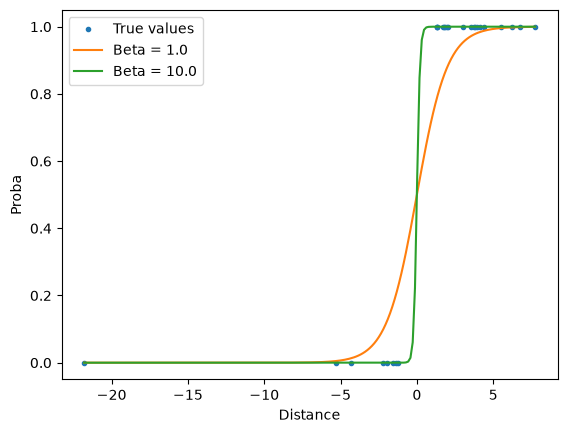

In [59]:
import matplotlib.pyplot as plt
from scipy.special import expit  # this is the logistic function

distances = sphere.decision_function(X)
plt.plot(distances, y, '.', label='True values')

distance_range = np.linspace(distances.min(), distances.max(), 200)

beta = (1., 10.)
for b in beta:
    # this is normally handled by .predict_proba
    # we use expit explictly here to trial different values for beta     
    plt.plot(distance_range, expit(b * distance_range), '-', label=f'Beta = {b}')
plt.xlabel('Distance')
plt.ylabel('Proba')
plt.legend()
plt.show()

Different values for beta can be set when instantiating `ClassicSphere`, so let's go ahead and fit a sphere with a smaller value for beta.

In [60]:
sphere_beta_1 = ClassicSphere(beta=1).fit(X, y)
sphere_beta_1.coef_

dD        21.271918
dP         7.709650
dH         9.111393
radius    13.667947
dtype: float64

Comparing this to our previous fit we can see the dD, dH and radius parameters have reduced a little, and there is a bigger (but not drastic) reduction on dP. The 'best' fit for the sphere will depend on the value of beta selected, but fundamentally it adjusts the confidence of the model in assigning a sample soluble or insoluble.

The value used for beta during fitting is stored in the `beta_` attribute; any change must be followed by refitting the sphere.

In [61]:
sphere_beta_1.set_params(beta=5.0)
sphere_beta_1.beta, sphere_beta_1.beta_

(5.0, 1.0)



#### Fitting beta
An additional option is to determine the optimium value for beta during the fit by passing `beta='fit'`. With this example data it's possible to achieve perfect separation and the optimum value for `beta` reaches 10.0, which is the maximum value and also our default. To demonstrate fitting we enable fitting using the squared distance metric. Now we can see `beta` takes a value of ~0.46.


In [62]:
sphere_beta_fit = ClassicSphere(beta='fit', squared_dist=True).fit(X, y)
sphere_beta_fit.beta_

0.49954439297041653

Fitting beta introduces an extra parameter to optimise and is best reserved for when a resonable number of samples exist. In addition, this functionality is only likely to have practical use when the sphere boundary is ill-defined, that is, when there are 'Wrong In' or 'Wrong Out' solvents (to use HSPiP terminology).

### Regularisation

When we ran this example in HSPiP we obtained these results:
```
dD = 18.7
dP = 7.8
dH = 6.9
radius = 9.3
```
So why do our results differ? Our choice of logistic fitting means the model tries to balance the radius between good and bad solvents, whereas in Hansen's method the radius is defined as the minimum value that encompasses all the good solvents. If there were a high number of samples and a blurred boundary (some solvents get misclassified) both methods would probably return similar results. In this case where there is clear delineation, our model chooses a bigger sphere that fits somewhere between the good and bad solvents.

If you want to control the size of the sphere, there is a regularisation parameter `alpha`. Setting a negative number decreases the size of sphere giving more cautious results similar to HSPiP; setting a positive number increases the size which may be useful if trying to explore solubility boundaries. Using a value of -2 gives us values closer to those from HSPiP. Not the same, the models are still fundamentally different, but both are equally valid.

In [63]:
sphere_with_alpha = ClassicSphere(alpha=-2).fit(X, y)
sphere_with_alpha.coef_

dD        18.974941
dP         7.679444
dH         7.182991
radius     9.521891
dtype: float64

### Multiple fits
With each call to `fit()` we run several fitting routines with different starting conditions. The number of fits can be controlled with the `n_fits` hyperparameter. The selected `coef_` are the ones that give the best fit (by minimising the loss function). The results of all the fits, including the loss, are available with the `fit_results_` attribute. Most of the time the result is nearly the same for the best fits, which can give an idea of how well defined the sphere is.



In [64]:
sphere.fit_results_

,dD,dP,dH,radius,loss
0,21.796383,8.301431,9.333167,14.323261,0.000010
1,21.784296,8.262076,9.347264,14.295578,0.000010
2,21.766814,8.259454,9.334470,14.268296,0.000010
3,21.803297,8.230283,9.349449,14.322766,0.000010
4,21.877021,8.336788,9.330042,14.461865,0.000010
5,21.785883,8.207005,9.355374,14.286947,0.000010
6,21.845153,8.382397,9.316523,14.417345,0.000010
7,21.892452,8.384170,9.307952,14.499746,0.000010
8,21.780021,8.354599,9.308651,14.313031,0.000010
9,21.811628,8.396643,9.270577,14.373089,0.000010


Sometimes the optimiser can settle into a different minimum which could be another valid solution. You can use your judgement if that happens, which may mean obtaining more data to better define the sphere. The exploration of the Hansen coordinate space can be further controlled using the `initialisation` and `init_sigma` hyperparameters of the `ClassicSphere` class.

## Evaluating fits

### Scoring
`ClassicSphere` is a scikit-learn classifier and is therefore compatible with scikit-learn methods for model evaluation. We'll demonstrate using the confusion matrix here. 

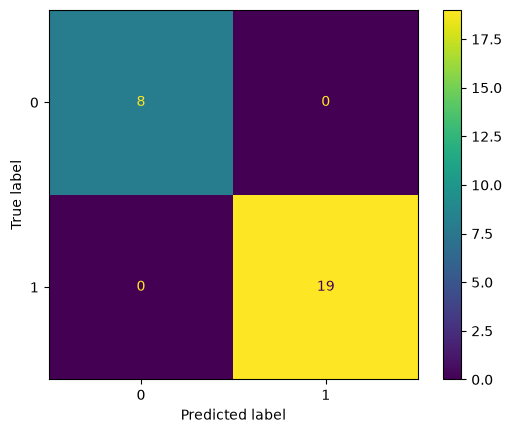

In [65]:
from sklearn.metrics import ConfusionMatrixDisplay

predicted = sphere_beta_fit.predict(X)
ConfusionMatrixDisplay.from_predictions(y, predicted)

The confusion matrix (for a binary classifier) shows *true negatives* and *true positives* on the diagonal, and *false negatives* and *false positives* on the off-diagonal. HSPiP provides the same information, using the terminology 'Wrong In' for a false positive and 'Wrong Out' for a false negative. As you can see in this case all the predictions were correct. Lets check the result for `sphere_with_alpha` (it's the same):

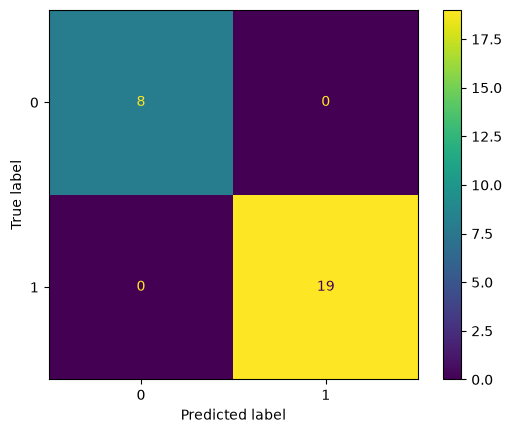

In [66]:
ConfusionMatrixDisplay.from_predictions(y, sphere_with_alpha.predict(X))

The information from the confusion matrix can be used to compute the [*F1 score*](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html). The F1 score has a maximum value of 1 for perfect classification. This is implemented as the default scoring metric in the `ClassicSphere.score()` method.

In [67]:
sphere.score(X, y)

1.0

### Cross Validation

In machine learning it is typical to evaluate the predictive value of models against a held out test set or by using cross validation rather than scoring against the data used to fit the model. With the small datasets typically used in HSP fitting a useful strategy to use *leave-one-out* cross validation. However, because in each split the test set has one sample, metrics such as the F1 score have no meaning when calculated on a per-split basis by `cross_validate` or `cross_val_score`. Instead we can compute a global F1 score using `cross_val_predict`.

In [68]:
from sklearn.model_selection import cross_val_predict, LeaveOneOut
from sklearn.metrics import f1_score

loo_predictions = cross_val_predict(sphere, X, y, cv=LeaveOneOut())
f1_score(y, loo_predictions)

0.9743589743589743

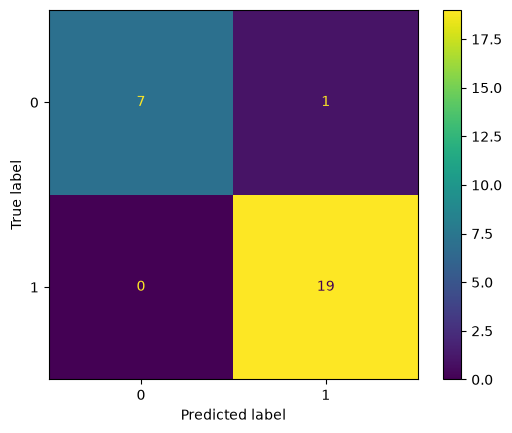

In [69]:
ConfusionMatrixDisplay.from_predictions(y, loo_predictions)

The cross validated results show that a prediction error was made on one fit, but with a still high F1 score of 0.97 we can rely on this model to make predictions for new samples.

Cross validation can also be used to study how sphere coefficients vary across fits and thus how well defined the sphere is. HSPiP has a similar feature, the results of which are given in the 'Core' result. Scikit-Learn's `cross_validate` function can be used for this provided that a single sample compatible scoring metric is used, such as `'accuracy'`.

In [70]:
from sklearn.model_selection import cross_validate
import pandas as pd

xval = cross_validate(sphere, X, y, cv=LeaveOneOut(), scoring='accuracy', return_estimator=True)

coefs = pd.DataFrame([est.coef_ for est in xval['estimator']])
coefs.describe()

,dD,dP,dH,radius
count,27.000000,27.000000,27.000000,27.000000
mean,21.842146,8.253297,9.456439,14.440681
std,0.350159,0.310640,0.697819,0.838591
min,21.231309,7.070915,8.797232,13.428350
25%,21.796356,8.269059,9.323303,14.318036
50%,21.811278,8.285556,9.332337,14.345753
75%,21.818818,8.292014,9.339337,14.359615
max,23.338296,9.205774,12.876082,18.320210


Inspecting these results we can see the middle 50% provides a narrow range for the coefficients across all the parameters. The minimum, maximum and standard deviation shows more spread, especially for the dH and radius parameters, indicative of a dataset skewed by one or two of the fits.